<a href="https://colab.research.google.com/github/azradogan170-sys/python-veri-gorsellestirme-projesi/blob/main/Gapminder_Veri_Gorsellestirme_Analizi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ödevim için ülkelerin yıllar içindeki ekonomik ve demografik gelişimini gösteren Gapminder veri setini seçtim. Bu veri setini seçmemin temel nedeni; içerisinde hem ülke ve kıta gibi kategorik verileri, hem yaşam süresi ve gelir gibi sayısal verileri, hem de 1952'den 2007'ye kadar uzanan zaman boyutunu barındırması. Ayrıca dışarıdan CSV dosyası indirmeye gerek kalmadan, doğrudan Plotly kütüphanesinin içinden tek satır kodla çekilebiliyor.

**Veri Kaynağı:** Gapminder Foundation (plotly.data.gapminder() fonksiyonu ile doğrudan erişilebilir)

**Web Linki:** [https://www.gapminder.org/data/](https://www.gapminder.org/data/)

**Veri Setindeki Sütunlar:**

**country:** Ülke adı (Kategorik)

**continent:** Ülkenin bulunduğu kıta - Asya, Avrupa, Afrika, Amerika, Okyanusya (Kategorik)

**year:** Verinin kaydedildiği yıl - 1952 ile 2007 arası 5'er yıllık periyotlar (Zaman)

**lifeExp:** Doğuşta beklenen ortalama yaşam süresi, yıl cinsinden (Sayısal)

**pop:** Ülke nüfusu (Sayısal)

**gdpPercap:** Kişi başına düşen milli gelir, ABD Doları cinsinden (Sayısal)

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import seaborn as sns

sns.set_theme(style="whitegrid")

df = px.data.gapminder()

print(df.info())
print("\nEksik Veri Sayısı:\n", df.isnull().sum())

df_2007 = df[df["year"] == 2007]

df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   object 
 1   continent  1704 non-null   object 
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   object 
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 106.6+ KB
None

Eksik Veri Sayısı:
 country      0
continent    0
year         0
lifeExp      0
pop          0
gdpPercap    0
iso_alpha    0
iso_num      0
dtype: int64


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4


Veri setini inceledikten sonra, 4 temel görselleştirme amacına ve zaman boyutuna uygun şu araştırma sorularını belirledim:

**Dağılım (Distribution):** 2007 yılında kıtalara göre ülkelerin beklenen yaşam süresi dağılımları, ortanca (medyan) değerleri ve uç değerleri nasıl farklılaşıyor?

**Karşılaştırma ve Zaman (Comparison & Time):** 1952'den 2007 yılına kadar geçen sürede, farklı kıtaların ortalama yaşam süreleri nasıl bir değişim gösterdi?

**İlişki (Relationship):** 2007 yılında ülkelerin kişi başına düşen milli geliri ile beklenen yaşam süresi arasında nasıl bir ilişki var ve ülke nüfusları bu durumu nasıl etkiliyor?

**Kompozisyon (Composition):** 2007 yılında dünya nüfusunun kıtalara ve ülkelere göre dağılım oranı (parça-bütün ilişkisi) nasıldır?

Grafik 1: Dağılım — Seaborn Kutu Grafiği

Soru 1: 2007 yılında kıtalara göre beklenen yaşam süresi dağılımı nasıldır?


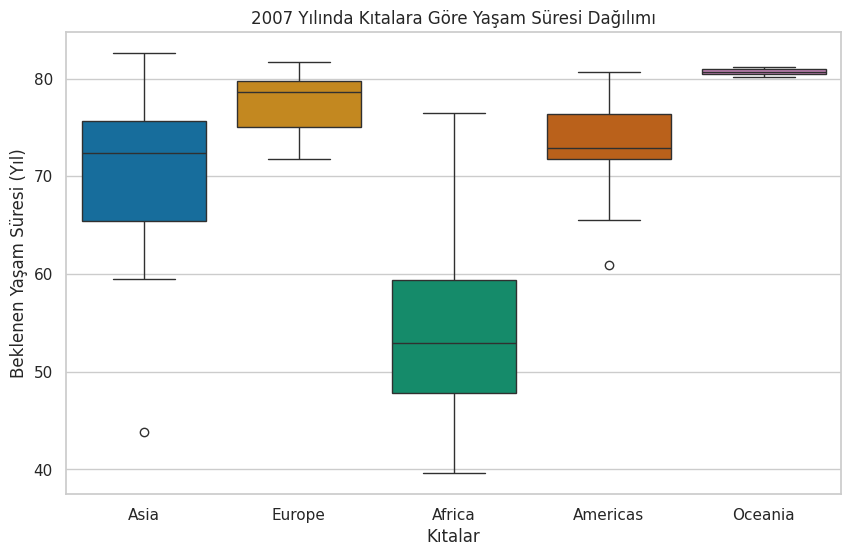

In [11]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_2007, x="continent", y="lifeExp", hue="continent", palette="colorblind", legend=False
)
plt.title("2007 Yılında Kıtalara Göre Yaşam Süresi Dağılımı")
plt.xlabel("Kıtalar")
plt.ylabel("Beklenen Yaşam Süresi (Yıl)")
plt.show()

**Neden bu grafiği seçtim?** Kıtalardaki yaşam sürelerinin sadece ortalamasını görmek yerine; verinin ne kadar yayıldığını, medyan değerini, çeyreklikleri ve aykırı değerleri tek seferde görebilmek için Kutu Grafiği tercih ettim.

**Temel Bulgu:** Grafiğe baktığımda Avrupa ve Okyanusya'da yaşam süresinin oldukça yüksek ve bu kıtalardaki ülkelerin yaşam standartları birbirine çok yakın. Afrika ise hem en düşük medyan değere sahip hem de kutu boyu çok geniş, bu da kıta içindeki ülkeler arasında büyük bir eşitsizlik olduğunu gösteriyor. Ayrıca Asya kıtasında en altta tek başına duran bir uç değer (Afganistan) dikkat çekiyor.

Grafik 2: Karşılaştırma ve Zaman — Seaborn Çizgi Grafiği

Soru 2: 1952-2007 yılları arasında kıtaların ortalama yaşam süreleri nasıl değişti?

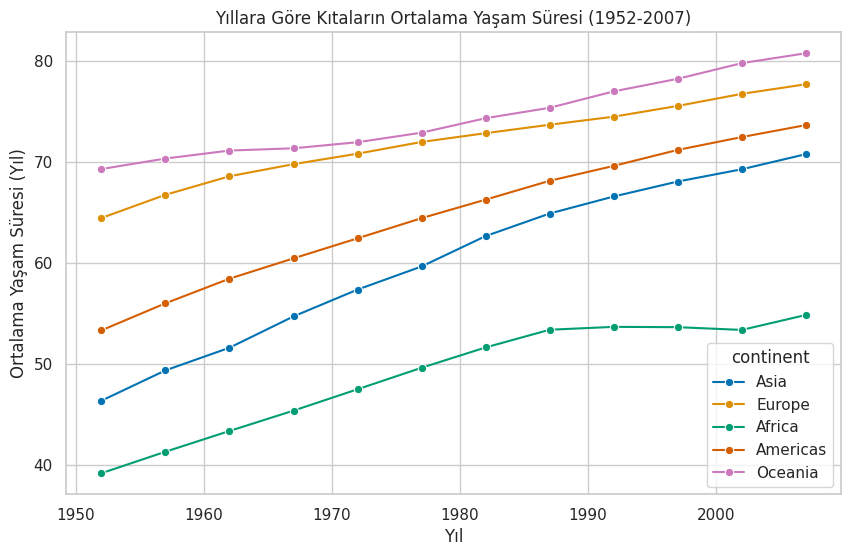

In [12]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=df,
    x="year",
    y="lifeExp",
    hue="continent",
    marker="o",
    errorbar=None,
    palette="colorblind",
)
plt.title("Yıllara Göre Kıtaların Ortalama Yaşam Süresi (1952-2007)")
plt.xlabel("Yıl")
plt.ylabel("Ortalama Yaşam Süresi (Yıl)")
plt.show()

**Neden bu grafiği seçtim?** Zaman içindeki sürekli bir değişimi görmek ve 5 farklı kıtayı aynı zaman çizelgesi üzerinde karşılaştırmak için en uygun grafik türü Çizgi Grafiği olduğu için bunu kullandım.

**Temel Bulgu:** 1952'den 2007'ye kadar tüm kıtalarda yaşam süresi artmış. En hızlı yükselişi Asya kıtası yakalamış. Ancak Afrika'da 1980'lerin sonundan 2000'lerin başına kadar yükselişin tamamen durmuş.

Grafik 3: İlişki — Plotly Baloncuk Grafiği

Soru 3: 2007 yılında ülkelerin kişi başı geliri ile yaşam süresi arasında nasıl bir ilişki vardır?

In [13]:
fig = px.scatter(
    df_2007,
    x="gdpPercap",
    y="lifeExp",
    size="pop",
    color="continent",
    hover_name="country",
    log_x=True,
    size_max=50,
    title="2007 Yılında Kişi Başı Gelir ve Yaşam Süresi İlişkisi",
    labels={
        "gdpPercap": "Kişi Başı GSYİH ($, Log Ölçek)",
        "lifeExp": "Beklenen Yaşam Süresi (Yıl)",
        "continent": "Kıta",
    },
)
fig.show()

Neden bu grafiği seçtim? Gelir ve yaşam süresi arasındaki korelasyonu görmek için Dağılım Grafiği seçtim. Ancak analize ülke nüfusunu ve kıta bilgisini de katmak istediğim için bunu bir Baloncuk Grafiği yapısına dönüştürdüm. Gelir dağılımında ülkeler arasında uçurum olduğu için X eksenini logaritmik yaptım; böylece düşük gelirli ülkeler sol köşede üst üste binmedi.

**Temel Bulgu:** Gelir arttıkça beklenen yaşam süresinin de belirgin şekilde arttığını gözlemledim. Düşük gelirli Afrika ülkeleri sol alt köşede toplanırken, yüksek gelirli Avrupa ülkeleri sağ üst köşede yer alıyor. Dev balonlarla temsil edilen Çin ve Hindistan ise orta gelir düzeyinde olmalarına rağmen 65-73 yıl arası yaşam süreleri var.

Grafik 4: Kompozisyon — Plotly Ağaç Haritası

Soru 4: 2007 yılında dünya nüfusunun kıtalara ve ülkelere göre dağılım oranı nasıldır?

In [14]:
fig = px.treemap(
    df_2007,
    path=["continent", "country"],
    values="pop",
    color="continent",
    title="2007 Yılı Dünya Nüfusunun Kıtalara ve Ülkelere Göre Dağılımı",
    labels={"pop": "Nüfus", "continent": "Kıta"},
)
fig.show()

**Neden bu grafiği seçtim?** Amacım parça-bütün  ilişkisini göstermekti. Hem kıtaların toplam payını hem de içlerindeki ülkelerin büyüklüğünü tek bir alanda en iyi Ağaç Haritası gösterdiği için bu grafiği tercih ettim.

**Temel Bulgu:** Grafikte ilk bakışta Asya kıtasının dünya nüfusunun yarısından fazlasını tek başına oluşturduğu görülüyor. Özellikle Çin ve Hindistan'ın kutu alanları o kadar büyük ki, bu iki ülkenin toplam nüfusu Avrupa, Amerika ve Okyanusya kıtalarının tamamının toplamından bile daha fazla yer kaplıyor.

**Hatalı Grafik Kodu**

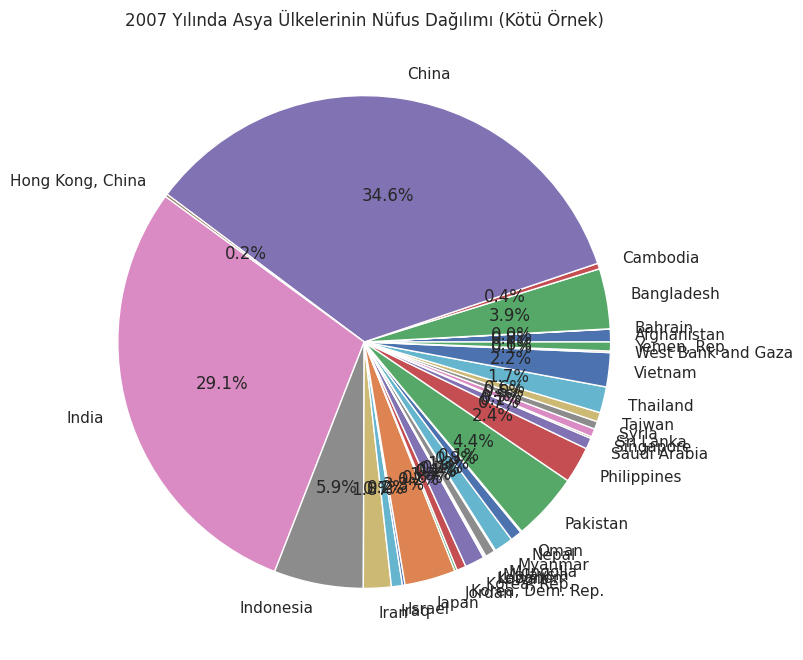

In [15]:
asya_2007 = df_2007[df_2007["continent"] == "Asia"]

plt.figure(figsize=(8, 8))
plt.pie(asya_2007["pop"], labels=asya_2007["country"], autopct="%1.1f%%")
plt.title("2007 Yılında Asya Ülkelerinin Nüfus Dağılımı (Kötü Örnek)")
plt.show()

**Bu Grafik Neden Yanlış?**
Çok Dilimli Pasta Grafiği Hatası:

Asya kıtasındaki 33 ülkenin nüfusunu pasta grafiği ile çizdirdim. Pasta grafikleri en fazla 4-5 kategori olduğunda anlamlıdır. 33 ülkeyi tek bir pastaya koyduğumda Çin ve Hindistan dışındaki küçük ülkelerin dilimleri birbirine girdi, ülke isimleri ve yüzdeler üst üste binerek tamamen okunaksız bir görsel oluşturdu.